# Остывание нагретого участка стержня

В зелёной работе начальный профиль был гладким. Теперь зададим $u=1$ при $0.4\leq x\leq0.6$ и $u=0$ вне нагретого участка. Уравнение и закреплённые температуры на концах прежние:
$$u_t=u_{xx},\qquad u(0,t)=u(1,t)=0.$$

Добавим схему Кранка–Николсона и сравним её с неявным Эйлером при $r=\Delta t/\Delta x^2=0.4$, $2$ и $10$. Явную FTCS используем только при $r=0.4$. Отрицательные значения и другие отклонения решения оставляем без исправления.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import re

plt.rcParams.update({
    "figure.dpi": 85, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.25,
    "animation.embed_limit": 50,
})
N = 100
x = np.linspace(0, 1, N + 1)
dx = 1.0 / N
T = 0.02
ratios = [0.4, 2.0, 10.0]
implicit_methods = ["Неявный Эйлер", "Кранк–Николсон"]
theta_values = {"FTCS": 0.0, "Неявный Эйлер": 1.0, "Кранк–Николсон": 0.5}
method_colors = {"FTCS": "#21855b", "Неявный Эйлер": "#2563eb", "Кранк–Николсон": "#df7620"}
initial = ((x >= 0.4) & (x <= 0.6)).astype(float)


## 1. Три схемы на одной сетке

Обозначим $Lu_j=u_{j-1}-2u_j+u_{j+1}$. Все три схемы можно записать как
$$(I-\vartheta rL)u^{n+1}=(I+(1-\vartheta)rL)u^n.$$
Для FTCS $\vartheta=0$, для неявного Эйлера $\vartheta=1$, для Кранка–Николсона $\vartheta=1/2$. В неявных случаях решаем трёхдиагональную систему прогонкой.

Сетку оставляем одной и той же: 100 интервалов, $\Delta x=0.01$. Временные шаги равны $0.00004$, $0.0002$ и $0.001$. Сравниваем методы при одинаковом физическом времени; выбранные моменты кратны всем трём шагам.


In [2]:
def factor(size, alpha):
    diagonal = np.empty(size)
    diagonal[0] = 1 + 2*alpha
    for i in range(1, size):
        diagonal[i] = 1 + 2*alpha - alpha**2/diagonal[i-1]
    return diagonal


def tridiagonal_solve(rhs, alpha, diagonal):
    result = rhs.copy()
    for i in range(1, len(result)):
        result[i] += alpha*result[i-1]/diagonal[i-1]
    result[-1] /= diagonal[-1]
    for i in range(len(result)-2, -1, -1):
        result[i] = (result[i] + alpha*result[i+1])/diagonal[i]
    return result


def solve(method, r):
    if method == "FTCS" and r > 0.5:
        raise ValueError("Для FTCS в этой работе используется только устойчивый шаг.")
    theta = theta_values[method]
    dt = r*dx**2
    count = int(round(T/dt))
    if not np.isclose(count*dt, T, rtol=0, atol=1e-12):
        raise ValueError("Конечный момент должен лежать на временной сетке.")
    time = np.arange(count+1)*dt
    U = np.zeros((count+1, N+1))
    U[0] = initial
    diagonal = factor(N-1, theta*r) if theta else None
    for n in range(count):
        u = U[n]
        rhs = u[1:-1] + (1-theta)*r*(u[:-2] - 2*u[1:-1] + u[2:])
        U[n+1, 1:-1] = (tridiagonal_solve(rhs, theta*r, diagonal) if theta else rhs)
    return {"t": time, "dt": dt, "U": U}


def at(result, time):
    i = int(round(time/result["dt"]))
    if not np.isclose(result["t"][i], time, rtol=0, atol=1e-12):
        raise ValueError("Момент не лежит на временной сетке.")
    return result["U"][i]


runs = {(method, r): solve(method, r) for method in implicit_methods for r in ratios}
runs["FTCS", 0.4] = solve("FTCS", 0.4)


## 2. Расчёт на малом временном шаге

За опорный возьмём Кранк–Николсон при $r=0.05$, то есть $\Delta t=5\cdot10^{-6}$. Повторим его с шагом вдвое меньше и сравним результаты в общие моменты через $0.001$.

Все расчёты используют одну пространственную сетку и одно начальное состояние. Поэтому отличие от опорного решения характеризует ошибку интегрирования по времени; пространственная ошибка остаётся общей.


In [3]:
reference = solve("Кранк–Николсон", 0.05)
reference_half = solve("Кранк–Николсон", 0.025)
common_times = np.arange(21)*0.001
reference_common = np.array([at(reference, tt) for tt in common_times])
reference_half_common = np.array([at(reference_half, tt) for tt in common_times])
reference_difference = np.max(np.abs(reference_common-reference_half_common))
print(f"Максимальное отличие двух опорных расчётов в общие моменты: {reference_difference:.3e}.")

print("\n    t        Метод                r       E_inf       min u       max u")
for tt in [0.001, 0.02]:
    for (method, r), result in runs.items():
        u = at(result, tt)
        E = np.max(np.abs(u-at(reference, tt)))
        print(f"{tt:7.3f}   {method:19s} {r:5.1f}  {E:11.4e}  {u.min():10.6f}  {u.max():10.6f}")


Максимальное отличие двух опорных расчётов в общие моменты: 4.721e-07.

    t        Метод                r       E_inf       min u       max u
  0.001   Неявный Эйлер         0.4   2.7867e-03    0.000000    0.979352
  0.001   Неявный Эйлер         2.0   1.3714e-02    0.000000    0.974889
  0.001   Неявный Эйлер        10.0   6.2135e-02    0.000000    0.963813
  0.001   Кранк–Николсон        0.4   3.9613e-05    0.000000    0.980760
  0.001   Кранк–Николсон        2.0   1.1817e-02    0.000000    0.981220
  0.001   Кранк–Николсон       10.0   3.2678e-01    0.000000    0.981476
  0.001   FTCS                  0.4   2.7960e-03    0.000000    0.982278
  0.020   Неявный Эйлер         0.4   2.4840e-04    0.000000    0.400799
  0.020   Неявный Эйлер         2.0   1.2445e-03    0.000000    0.401795
  0.020   Неявный Эйлер        10.0   6.2819e-03    0.000000    0.406833
  0.020   Кранк–Николсон        0.4   1.8618e-07    0.000000    0.400551
  0.020   Кранк–Николсон        2.0   4.7251e-06    0

## 3. Первые слои и края нагретого участка

Рассмотрим $t=0.001$, $0.002$ и $0.003$. Для $r=10$ это первые три временных слоя; для меньших шагов к этим же моментам выполнено больше шагов. Чёрная пунктирная линия — опорный расчёт.

После общих профилей увеличим оба края при $t=0.001$. Во всех увеличенных фрагментах одинаковы масштабы температуры и ширина окна.


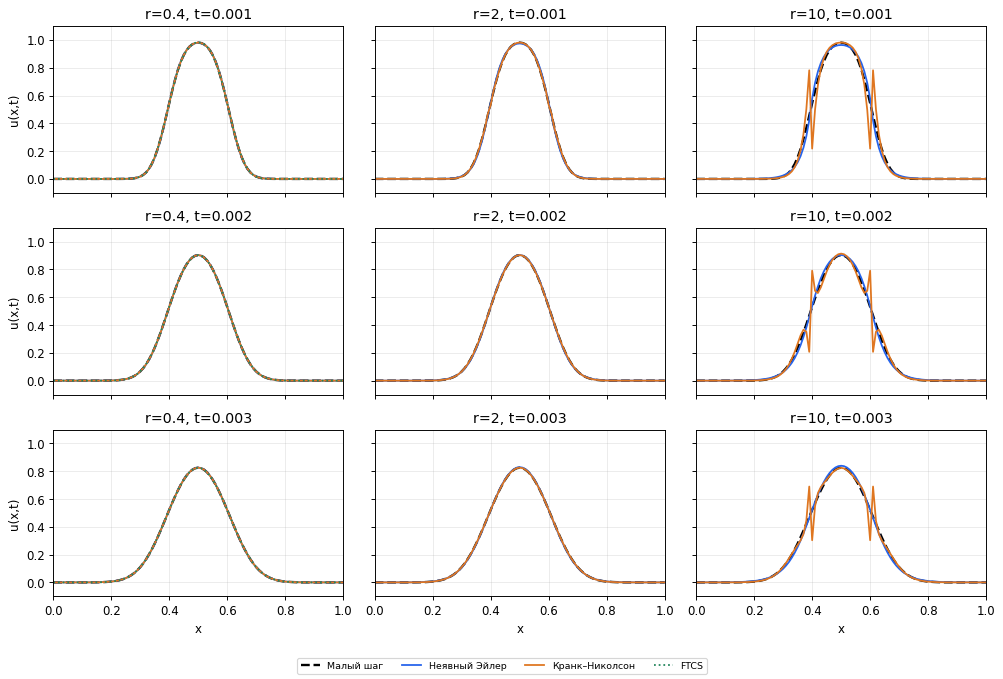

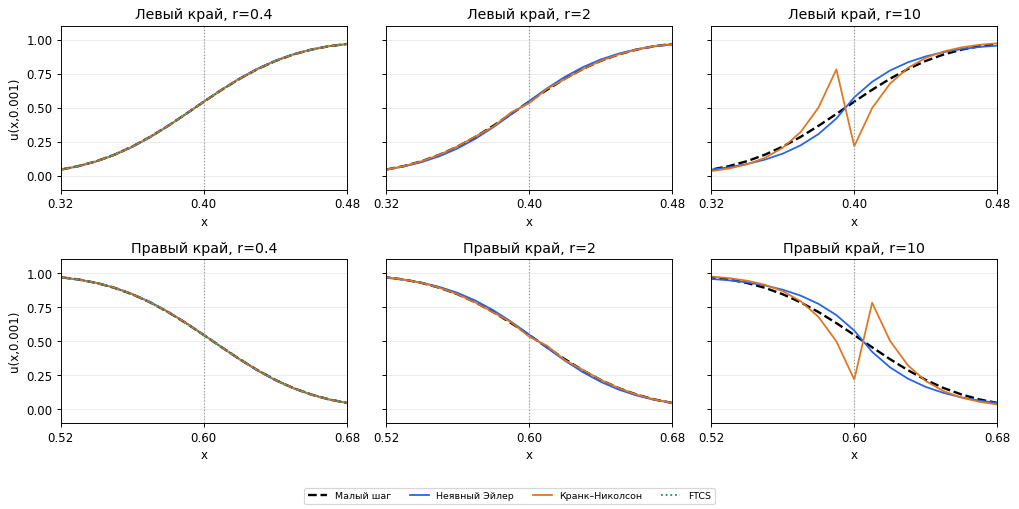

In [4]:
def draw_profile(a, r, tt):
    a.plot(x, at(reference, tt), "k--", lw=2, label="Малый шаг")
    for method in implicit_methods:
        a.plot(x, at(runs[method, r], tt), color=method_colors[method], label=method)
    if r == 0.4:
        a.plot(x, at(runs["FTCS", r], tt), ":", color=method_colors["FTCS"], label="FTCS")


fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True, sharey=True)
for row, tt in enumerate([0.001, 0.002, 0.003]):
    for col, r in enumerate(ratios):
        a = axes[row, col]
        draw_profile(a, r, tt)
        a.set(xlim=(0, 1), ylim=(-0.1, 1.1), title=f"r={r:g}, t={tt:g}")
        if row == 2:
            a.set_xlabel("x")
        if col == 0:
            a.set_ylabel("u(x,t)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8)
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for row, edge in enumerate([0.4, 0.6]):
    for col, r in enumerate(ratios):
        a = axes[row, col]
        draw_profile(a, r, 0.001)
        a.axvline(edge, color="0.6", ls=":", lw=1)
        a.set(xlim=(edge-0.08, edge+0.08), ylim=(-0.1, 1.1), xlabel="x",
              title=f"{'Левый' if row == 0 else 'Правый'} край, r={r:g}")
        a.set_xticks([edge-0.08, edge, edge+0.08])
        if col == 0:
            a.set_ylabel("u(x,0.001)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


При $r=10$ у Кранка–Николсона около границ появляются резкие изломы: соседние узлы по разные стороны скачка временно меняются местами по температуре. На следующем слое картина частично переворачивается. У неявного Эйлера переход плавнее, но большое значение шага заметно меняет профиль относительно опорного решения.

На первом крупном слое, при $r=10$ и $t=0.001$, ошибка Кранка–Николсона относительно малого шага равна примерно $0.327$, а неявного Эйлера — $0.062$. Температура в узле $x=0.4$ у Кранка–Николсона на первых трёх слоях принимает значения $0.218$, $0.791$ и $0.303$.


## 4. Экстремумы и температура на краю

Построим минимум и максимум во всей области, включая концы стержня. Затем посмотрим на узел $x=0.4$ и ошибку относительно малого шага. На всех временных графиках используются одни моменты $t=0,0.001,\ldots,0.02$.

Цвет кривой обозначает $r$. Неявный Эйлер показан пунктиром, Кранк–Николсон — сплошной линией, FTCS — точечной.


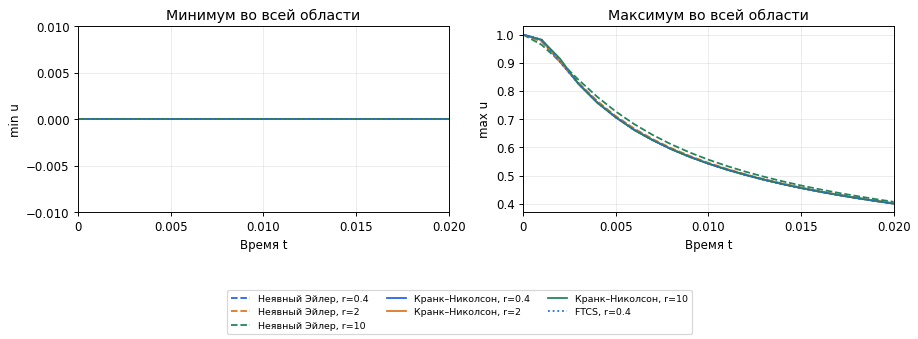

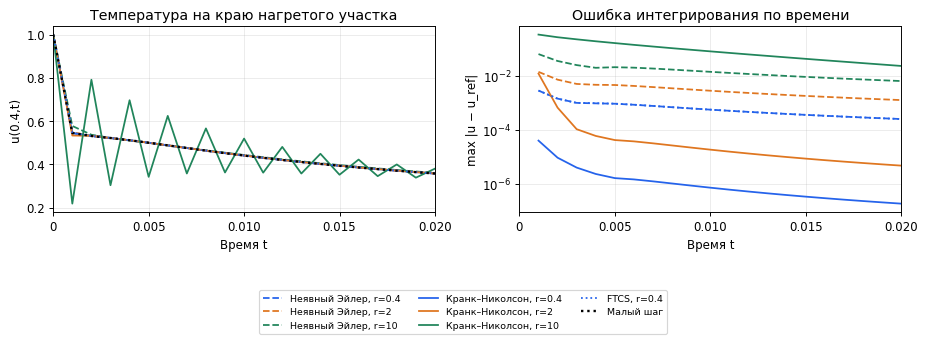

In [5]:
r_colors = {0.4: "#2563eb", 2.0: "#df7620", 10.0: "#21855b"}
styles = {"Неявный Эйлер": "--", "Кранк–Николсон": "-", "FTCS": ":"}
common = {key: np.array([at(result, tt) for tt in common_times]) for key, result in runs.items()}
errors = {key: np.max(np.abs(values-reference_common), axis=1) for key, values in common.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (method, r), values in common.items():
    label = f"{method}, r={r:g}"
    axes[0].plot(common_times, values.min(axis=1), styles[method], color=r_colors[r], label=label)
    axes[1].plot(common_times, values.max(axis=1), styles[method], color=r_colors[r], label=label)
axes[0].set(xlabel="Время t", ylabel="min u", title="Минимум во всей области", ylim=(-0.01, 0.01))
axes[1].set(xlabel="Время t", ylabel="max u", title="Максимум во всей области")
for a in axes:
    a.set_xlim(0, T)
    a.set_xticks([0, 0.005, 0.01, 0.015, 0.02], ["0", "0.005", "0.010", "0.015", "0.020"])
fig.legend(*axes[1].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8)
fig.tight_layout(rect=[0, 0.21, 1, 1])
plt.show()

edge_index = int(round(0.4/dx))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (method, r), values in common.items():
    label = f"{method}, r={r:g}"
    axes[0].plot(common_times, values[:, edge_index], styles[method], color=r_colors[r], label=label)
    axes[1].semilogy(common_times[1:], errors[method, r][1:], styles[method], color=r_colors[r], label=label)
axes[0].plot(common_times, reference_common[:, edge_index], "k:", lw=2, label="Малый шаг")
axes[0].set(xlabel="Время t", ylabel="u(0.4,t)", title="Температура на краю нагретого участка")
axes[1].set(xlabel="Время t", ylabel="max |u − u_ref|", title="Ошибка интегрирования по времени")
for a in axes:
    a.set_xlim(0, T)
    a.set_xticks([0, 0.005, 0.01, 0.015, 0.02], ["0", "0.005", "0.010", "0.015", "0.020"])
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8)
fig.tight_layout(rect=[0, 0.21, 1, 1])
plt.show()


На этой сетке все рассчитанные температуры остались между 0 и 1. Минимум во всей области равен нулю, поскольку концы стержня закреплены. Но по графику $u(0.4,t)$ видно, что Кранк–Николсон при $r=10$ даёт затухающую раскачку. Одних общих экстремумов для её обнаружения недостаточно.


## 5. Изменение профиля во времени

В анимации показаны те же общие моменты через $0.001$. Это отдельные временные слои: их удобно просматривать ползунком, особенно в начале расчёта при $r=10$.


In [6]:
def show_animation(animation):
    html = animation.to_jshtml(fps=6, default_mode="once")
    html = re.sub(r'<link\b[^>]*font-awesome[^>]*>', '', html)
    icons = {
        "fa fa-minus": "−", "fa fa-plus": "+",
        "fa fa-fast-backward": "⏮", "fa fa-step-backward": "⏪",
        "fa fa-play fa-flip-horizontal": "◀", "fa fa-play": "▶",
        "fa fa-pause": "⏸", "fa fa-step-forward": "⏩",
        "fa fa-fast-forward": "⏭",
    }
    for css, symbol in icons.items():
        html = html.replace(f'<i class="{css}"></i>', f'<span>{symbol}</span>')
    display(HTML(html))


fig, axes = plt.subplots(3, 1, figsize=(9.5, 7), sharex=True, sharey=True)
lines = []
for a, r in zip(axes, ratios):
    reference_line, = a.plot(x, initial, "k--", lw=2, label="Малый шаг")
    method_lines = []
    chosen = implicit_methods + (["FTCS"] if r == 0.4 else [])
    for method in chosen:
        line, = a.plot(x, initial, ":" if method == "FTCS" else "-",
                       color=method_colors[method], label=method)
        method_lines.append((method, line))
    lines.append((reference_line, method_lines))
    a.set(xlim=(0, 1), ylim=(-0.1, 1.1), ylabel="u", title=f"r={r:g}")
axes[-1].set_xlabel("x")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(0.5, 0.95), ncol=4, fontsize=8)
clock = fig.suptitle("t = 0.000", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.89])


def update(k):
    for r, (reference_line, method_lines) in zip(ratios, lines):
        reference_line.set_ydata(reference_common[k])
        for method, line in method_lines:
            line.set_ydata(common[method, r][k])
    clock.set_text(f"t = {common_times[k]:.3f}")
    return clock,


animation = FuncAnimation(fig, update, frames=len(common_times), interval=1000/6)
plt.close(fig)
show_animation(animation)


## Вывод

**Гарантирует ли безусловная устойчивость точность и отсутствие осцилляций?**

Нет. Устойчивость ограничивает рост ошибок, но не делает большой временной шаг точным. Неявный Эйлер при больших $r$ сильнее искажает скорость затухания, а Кранк–Николсон может давать затухающие осцилляции около исходного скачка.

Для пространственной моды с волновым числом $q$ множители за шаг равны
$$G_E=\frac{1}{1+4r\sin^2(q/2)},\qquad
G_{CN}=\frac{1-2r\sin^2(q/2)}{1+2r\sin^2(q/2)}.$$
У неявного Эйлера множитель положителен. У Кранка–Николсона при больших $r$ высокочастотные моды меняют знак на каждом шаге. Их модуль не превосходит единицы, но близок к ней: при $r=10$ для самой высокой частоты $G_{CN}\approx-0.905$. Такая составляющая затухает медленно и вызывает раскачку, видимую на первых слоях.

В нашем расчёте отрицательных температур не возникло, однако изломы профиля и колебания на краю хорошо заметны. Проверка малым шагом нужна даже при устойчивой схеме.
